# Product Sales by Region: End-to-End Data Analysis

**Dataset:** `Product-Sales-Region.xlsx` (1,500 orders, Jan 2023 – Jun 2025, 19 columns)

**Pipeline**
1. Setup and loading
2. Data cleaning and validation
3. Feature engineering
4. Exploratory data analysis (EDA)
5. Business performance analysis
6. Statistical testing
7. Storytelling: findings, recommendations, and caveats

**Business questions**
- How much revenue do we make, and how much of it is lost to returns?
- Which regions, products, channels and salespeople perform best?
- Is performance changing over time?
- Do discounts and promotions actually help?
- Which differences are real, and which are just noise?

## 1. Setup and Imports

Imports the libraries used in the analysis and sets a consistent plotting style. The random seed is fixed so bootstrap results can be reproduced.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
PALETTE = sns.color_palette("deep")

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

OUT = Path("outputs")          # cleaned data and summary tables are saved here
OUT.mkdir(exist_ok=True)

print("Libraries ready. pandas", pd.__version__, "| numpy", np.__version__)

Libraries ready. pandas 2.2.3 | numpy 1.26.4


## 2. Load the Data

Reads the single worksheet (`Sheet1`) into a DataFrame. The code looks for the file next to the notebook first, then at the uploaded location.

**Note:** `raw` is kept as an untouched copy. All cleaning happens on `df`, so the original data is never overwritten.

In [2]:
CANDIDATE_PATHS = [
    Path("Product-Sales-Region.xlsx"),
    Path("/mnt/user-data/attachments/28404bbc-effb-5eeb-9c60-a021889a666b/36ea356d-Product-Sales-Region.xlsx"),
]
DATA_PATH = next((p for p in CANDIDATE_PATHS if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Place Product-Sales-Region.xlsx in the same folder as this notebook.")

raw = pd.read_excel(DATA_PATH)            # untouched copy
df = raw.copy()                           # working copy

print(f"Loaded: {DATA_PATH}")
print(f"Shape : {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Loaded: Product-Sales-Region.xlsx
Shape : 1,500 rows x 19 columns


,Date,Region,Product,Quantity,UnitPrice,StoreLocation,CustomerType,Discount,Salesperson,TotalPrice,PaymentMethod,Promotion,Returned,OrderID,CustomerName,ShippingCost,OrderDate,DeliveryDate,RegionManager
0,2023-02-23,East,Laptop,14,163.60,Store B,Wholesale,0.00,Eva,2290.400,Online,FREESHIP,0,REG100000,Cust 6583,43.34,2023-02-23,2023-02-27,Eric
1,2024-12-19,South,Phone,1,544.01,Store A,Retail,0.00,Alice,544.010,Gift Card,SAVE10,0,REG100001,Cust 2144,5.30,2024-12-19,2024-12-28,Sophie
2,2023-05-10,North,Desk,14,346.18,Store B,Wholesale,0.10,Alice,4361.868,Online,WINTER15,0,REG100002,Cust 5998,20.46,2023-05-10,2023-05-19,Ryan
3,2025-02-26,Central,Chair,18,384.82,Store A,Wholesale,0.15,Frank,5887.746,Gift Card,FREESHIP,0,REG100003,Cust 7136,27.95,2025-02-26,2025-03-02,Cameron
4,2023-06-24,East,Desk,18,237.76,Store C,Retail,0.00,Carlos,4279.680,Online,SAVE10,0,REG100004,Cust 6506,5.73,2023-06-24,2023-06-27,Eric


### 2.1 First Look: Structure and Data Dictionary

Checks column types, memory use and the non-null count for each column. This shows where cleaning is needed before anything else.

| Column | Meaning |
|---|---|
| `Date` / `OrderDate` | Order date (duplicate columns) |
| `DeliveryDate` | Date the order was delivered |
| `Region`, `RegionManager` | Sales region and the manager responsible for it |
| `StoreLocation` | Store that fulfilled the order |
| `Product` | Product category (Laptop, Phone, Tablet, Monitor, Printer, Desk, Chair) |
| `Quantity`, `UnitPrice` | Units ordered and price per unit |
| `Discount` | Fractional discount applied (0 to 0.15) |
| `TotalPrice` | Final order value after discount |
| `ShippingCost` | Shipping charge for the order |
| `CustomerType`, `CustomerName` | Retail vs Wholesale, and customer identifier |
| `Salesperson` | Salesperson who took the order |
| `PaymentMethod`, `Promotion` | How the customer paid, and promo code used |
| `Returned` | 1 = order was returned, 0 = not returned |
| `OrderID` | Unique order identifier |

In [3]:
raw.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           1500 non-null   datetime64[ns]
 1   Region         1500 non-null   object        
 2   Product        1500 non-null   object        
 3   Quantity       1500 non-null   int64         
 4   UnitPrice      1500 non-null   float64       
 5   StoreLocation  1500 non-null   object        
 6   CustomerType   1500 non-null   object        
 7   Discount       1500 non-null   float64       
 8   Salesperson    1500 non-null   object        
 9   TotalPrice     1500 non-null   float64       
 10  PaymentMethod  1500 non-null   object        
 11  Promotion      1130 non-null   object        
 12  Returned       1500 non-null   int64         
 13  OrderID        1500 non-null   object        
 14  CustomerName   1500 non-null   object        
 15  ShippingCost   1500 n

In [4]:
raw.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Date,1500,NaN,NaN,NaN,2024-04-07 21:35:02.400000256,2023-01-01 00:00:00,2023-08-20 00:00:00,2024-04-08 12:00:00,2024-12-07 06:00:00,2025-06-30 00:00:00,NaN
Region,1500,5,East,311,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product,1500,7,Tablet,240,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,1500.0,NaN,NaN,NaN,10.410667,1.0,5.0,11.0,15.0,20.0,5.735732
UnitPrice,1500.0,NaN,NaN,NaN,298.826947,5.52,151.02,294.74,446.7025,599.72,169.100075
StoreLocation,1500,4,Store D,400,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CustomerType,1500,2,Wholesale,756,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Discount,1500.0,NaN,NaN,NaN,0.073133,0.0,0.0,0.05,0.1,0.15,0.055979
Salesperson,1500,6,Carlos,270,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TotalPrice,1500.0,NaN,NaN,NaN,2919.994952,6.97,867.13625,2174.724,4414.7235,11077.0,2522.789977


## 3. Data Cleaning and Validation

Cleaning runs in this order:
1. Standardise column names and text values
2. Fix data types
3. Remove duplicates
4. Handle missing values
5. Validate business rules (quantities, prices, dates, returns)
6. Check that the derived `TotalPrice` is correct
7. Confirm the mapping between region and manager

### 3.1 Standardise Column Names and Text

Removes stray leading and trailing spaces from column names and from text values. Spacing mistakes like `"East "` and `"East"` would otherwise split one category into two when grouping.

In [5]:
df.columns = df.columns.str.strip()

text_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
for col in text_cols:
    df[col] = df[col].str.strip()

print("Text columns cleaned:", text_cols)
print("Column names:", df.columns.tolist())

Text columns cleaned: ['Region', 'Product', 'StoreLocation', 'CustomerType', 'Salesperson', 'PaymentMethod', 'Promotion', 'OrderID', 'CustomerName', 'RegionManager']
Column names: ['Date', 'Region', 'Product', 'Quantity', 'UnitPrice', 'StoreLocation', 'CustomerType', 'Discount', 'Salesperson', 'TotalPrice', 'PaymentMethod', 'Promotion', 'Returned', 'OrderID', 'CustomerName', 'ShippingCost', 'OrderDate', 'DeliveryDate', 'RegionManager']


### 3.2 Fix Data Types

Converts all date columns to proper datetime values. `errors="coerce"` turns any unreadable date into `NaT` (missing), so bad values are caught in the next step rather than causing a crash.

In [6]:
date_cols = ["Date", "OrderDate", "DeliveryDate"]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")

print("Unparseable dates per column:")
print(df[date_cols].isna().sum().to_string())
print("\nDtypes after conversion:")
print(df.dtypes.to_string())

Unparseable dates per column:
Date            0
OrderDate       0
DeliveryDate    0

Dtypes after conversion:
Date             datetime64[ns]
Region                   object
Product                  object
Quantity                  int64
UnitPrice               float64
StoreLocation            object
CustomerType             object
Discount                float64
Salesperson              object
TotalPrice              float64
PaymentMethod            object
Promotion                object
Returned                  int64
OrderID                  object
CustomerName             object
ShippingCost            float64
OrderDate        datetime64[ns]
DeliveryDate     datetime64[ns]
RegionManager            object


### 3.3 Remove Duplicates

Checks for two kinds of duplication: fully identical rows, and rows that reuse an `OrderID`. Each order should appear once, so any duplicate is removed.

In [7]:
n_before = len(df)
print("Fully duplicated rows :", df.duplicated().sum())
print("Duplicated OrderID    :", df["OrderID"].duplicated().sum())

df = df.drop_duplicates(subset="OrderID", keep="first").reset_index(drop=True)
print(f"\nRows: {n_before:,} -> {len(df):,}  (removed {n_before - len(df):,})")

Fully duplicated rows : 0
Duplicated OrderID    : 0

Rows: 1,500 -> 1,500  (removed 0)


### 3.4 Handle Missing Values

Lists missing values in every column. The `Promotion` column has blanks, which most likely mean **no promotion was applied**. Those blanks are relabelled `"None"` rather than dropped, since dropping would remove about 25% of the orders and bias the analysis. Any other missing values would be shown here and handled explicitly.

In [8]:
missing = (pd.DataFrame({"missing": df.isna().sum(), "pct_missing": df.isna().mean() * 100})
             .query("missing > 0"))
print("Columns with missing values:")
display(missing)

# Blank promotion = no promotion applied (a business decision, documented above)
df["Promotion"] = df["Promotion"].fillna("None")

print("Missing values after handling:", int(df.isna().sum().sum()))

Columns with missing values:


,missing,pct_missing
Promotion,370,24.666667


Missing values after handling: 0


### 3.5 Validate Business Rules

Checks every column against rules that should always hold:
- Quantity and unit price must be positive
- Discount must be between 0 and 1
- `Returned` must be 0 or 1
- Delivery cannot happen before the order
- Shipping cost cannot be negative
- The `Date` and `OrderDate` columns should match

Violations are counted, not silently dropped, so they can be reviewed.

In [9]:
rules = {
    "Quantity <= 0":              (df["Quantity"] <= 0).sum(),
    "UnitPrice <= 0":             (df["UnitPrice"] <= 0).sum(),
    "Discount outside [0, 1]":    ((df["Discount"] < 0) | (df["Discount"] > 1)).sum(),
    "Returned not in {0, 1}":     (~df["Returned"].isin([0, 1])).sum(),
    "DeliveryDate < OrderDate":   (df["DeliveryDate"] < df["OrderDate"]).sum(),
    "ShippingCost < 0":           (df["ShippingCost"] < 0).sum(),
    "Date != OrderDate":          (df["Date"] != df["OrderDate"]).sum(),
    "Missing dates (NaT)":        df[["Date", "OrderDate", "DeliveryDate"]].isna().sum().sum(),
}
rules_df = pd.Series(rules, name="violations").to_frame()
rules_df["status"] = np.where(rules_df["violations"] == 0, "PASS", "CHECK")
rules_df

,violations,status
Quantity <= 0,0,PASS
UnitPrice <= 0,0,PASS
"Discount outside [0, 1]",0,PASS
"Returned not in {0, 1}",0,PASS
DeliveryDate < OrderDate,0,PASS
ShippingCost < 0,0,PASS
Date != OrderDate,0,PASS
Missing dates (NaT),0,PASS


### 3.6 Verify the Derived `TotalPrice`

The dataset includes `TotalPrice`, which should equal `Quantity × UnitPrice × (1 − Discount)`. Recalculating it confirms the column is internally consistent. Any mismatch greater than one cent would be flagged.

In [10]:
expected_total = df["Quantity"] * df["UnitPrice"] * (1 - df["Discount"])
mismatch_mask = (expected_total - df["TotalPrice"]).abs() > 0.01

print(f"TotalPrice mismatches (> 1 cent): {mismatch_mask.sum()}")
print(f"Max absolute difference         : {(expected_total - df['TotalPrice']).abs().max():.6f}")

TotalPrice mismatches (> 1 cent): 0
Max absolute difference         : 0.000000


### 3.7 Check Category Consistency

Lists the unique values in each categorical column, so spelling variants or unexpected categories would show up. Then confirms that each region maps to exactly one regional manager.

In [11]:
cat_cols = ["Region", "Product", "StoreLocation", "CustomerType", "Salesperson",
            "PaymentMethod", "Promotion", "RegionManager"]

for col in cat_cols:
    print(f"{col:<15} ({df[col].nunique()} values): {sorted(df[col].unique())}")

print("\nRegion x RegionManager (should be one manager per region):")
display(pd.crosstab(df["Region"], df["RegionManager"]))

Region          (5 values): ['Central', 'East', 'North', 'South', 'West']
Product         (7 values): ['Chair', 'Desk', 'Laptop', 'Monitor', 'Phone', 'Printer', 'Tablet']
StoreLocation   (4 values): ['Store A', 'Store B', 'Store C', 'Store D']
CustomerType    (2 values): ['Retail', 'Wholesale']
Salesperson     (6 values): ['Alice', 'Bob', 'Carlos', 'Diana', 'Eva', 'Frank']
PaymentMethod   (5 values): ['Cash', 'Credit Card', 'Debit Card', 'Gift Card', 'Online']
Promotion       (4 values): ['FREESHIP', 'None', 'SAVE10', 'WINTER15']
RegionManager   (5 values): ['Cameron', 'Eric', 'Ryan', 'Sophie', 'Wendy']

Region x RegionManager (should be one manager per region):


RegionManager,Cameron,Eric,Ryan,Sophie,Wendy
Region,,,,,
Central,301,0,0,0,0
East,0,311,0,0,0
North,0,0,309,0,0
South,0,0,0,295,0
West,0,0,0,0,284


### 3.8 Remove Redundant Columns

`Date` is an exact copy of `OrderDate` (confirmed in 3.5), so it is dropped to avoid confusion. `RegionManager` is kept because it describes the same geography as `Region` and is useful for accountability reporting.

In [12]:
assert (df["Date"] == df["OrderDate"]).all(), "Date and OrderDate differ, do not drop!"
df = df.drop(columns=["Date"])
print("Dropped redundant column 'Date'. Remaining columns:", len(df.columns))

Dropped redundant column 'Date'. Remaining columns: 18


## 4. Feature Engineering

Creates new columns that make the analysis easier to read:

| New column | Definition | Why it matters |
|---|---|---|
| `Year`, `Month`, `Quarter`, `YearMonth` | Parts of `OrderDate` | Time-based grouping |
| `Half` | e.g. `2024-H1` | Fair comparison of partial periods (2025 has only H1) |
| `GrossSales` | `Quantity × UnitPrice` | Revenue before discount |
| `DiscountAmount` | `GrossSales − TotalPrice` | Money given away through discounts |
| `DeliveryDays` | `DeliveryDate − OrderDate` | Fulfilment speed |
| `NetRevenue` | `TotalPrice` for orders not returned, else 0 | Revenue actually kept |
| `ReturnedRevenue` | `TotalPrice` for returned orders | Revenue lost to returns |

In [13]:
df["Year"]        = df["OrderDate"].dt.year
df["Month"]       = df["OrderDate"].dt.month
df["Quarter"]     = df["OrderDate"].dt.to_period("Q").astype(str)
df["YearMonth"]   = df["OrderDate"].dt.to_period("M").dt.to_timestamp()
df["Half"]        = df["Year"].astype(str) + "-H" + np.where(df["Month"] <= 6, "1", "2")

df["GrossSales"]      = df["Quantity"] * df["UnitPrice"]
df["DiscountAmount"]  = df["GrossSales"] - df["TotalPrice"]
df["DeliveryDays"]    = (df["DeliveryDate"] - df["OrderDate"]).dt.days
df["NetRevenue"]      = np.where(df["Returned"] == 1, 0.0, df["TotalPrice"])
df["ReturnedRevenue"] = np.where(df["Returned"] == 1, df["TotalPrice"], 0.0)

new_cols = ["Year", "Month", "Quarter", "YearMonth", "Half", "GrossSales",
            "DiscountAmount", "DeliveryDays", "NetRevenue", "ReturnedRevenue"]
df[new_cols].head()

,Year,Month,Quarter,YearMonth,Half,GrossSales,DiscountAmount,DeliveryDays,NetRevenue,ReturnedRevenue
0,2023,2,2023Q1,2023-02-01,2023-H1,2290.40,0.000,4,2290.400,0.0
1,2024,12,2024Q4,2024-12-01,2024-H2,544.01,0.000,9,544.010,0.0
2,2023,5,2023Q2,2023-05-01,2023-H1,4846.52,484.652,9,4361.868,0.0
3,2025,2,2025Q1,2025-02-01,2025-H1,6926.76,1039.014,4,5887.746,0.0
4,2023,6,2023Q2,2023-06-01,2023-H1,4279.68,0.000,3,4279.680,0.0


### 4.1 Save the Cleaned Dataset

Writes the cleaned data to CSV so it can be reused without repeating the cleaning steps.

In [14]:
df.to_csv(OUT / "sales_clean.csv", index=False)
print(f"Saved {len(df):,} rows x {df.shape[1]} columns to {OUT / 'sales_clean.csv'}")
print("Date range:", df["OrderDate"].min().date(), "to", df["OrderDate"].max().date())

Saved 1,500 rows x 28 columns to outputs\sales_clean.csv
Date range: 2023-01-01 to 2025-06-30


## 5. Exploratory Data Analysis (EDA)

EDA looks at each variable on its own (univariate), then checks the shape of the numbers before any comparisons are made. Things to look for are skew, outliers and imbalance across categories.

### 5.1 Numeric Summary

Summary statistics for each numeric column, plus skewness. Skewness near 0 means symmetric. A large positive value means a long right tail, which is common for sales values.

In [15]:
num_cols = ["Quantity", "UnitPrice", "Discount", "GrossSales", "DiscountAmount",
            "TotalPrice", "ShippingCost", "DeliveryDays"]

num_summary = df[num_cols].describe().T
num_summary["skew"] = df[num_cols].skew()
num_summary.style.format("{:,.2f}")

,count,mean,std,min,25%,50%,75%,max,skew
Quantity,"1,500.00",10.41,5.74,1.00,5.00,11.00,15.00,20.00,0.00
UnitPrice,"1,500.00",298.83,169.10,5.52,151.02,294.74,446.70,599.72,0.02
Discount,"1,500.00",0.07,0.06,0.00,0.00,0.05,0.10,0.15,0.03
GrossSales,"1,500.00","3,151.93","2,712.31",8.20,917.25,"2,348.32","4,747.32","11,526.00",0.95
DiscountAmount,"1,500.00",231.93,306.50,-0.00,0.00,113.34,335.37,"1,698.69",1.89
TotalPrice,"1,500.00","2,919.99","2,522.79",6.97,867.14,"2,174.72","4,414.72","11,077.00",0.97
ShippingCost,"1,500.00",27.51,13.09,5.01,16.70,27.10,38.64,49.98,0.01
DeliveryDays,"1,500.00",6.04,2.54,2.00,4.00,6.00,8.00,10.00,-0.02


### 5.2 Distributions

Histograms show the shape of each numeric variable. `TotalPrice` is expected to be right-skewed, which is why the **median** is a better typical-order measure than the mean.

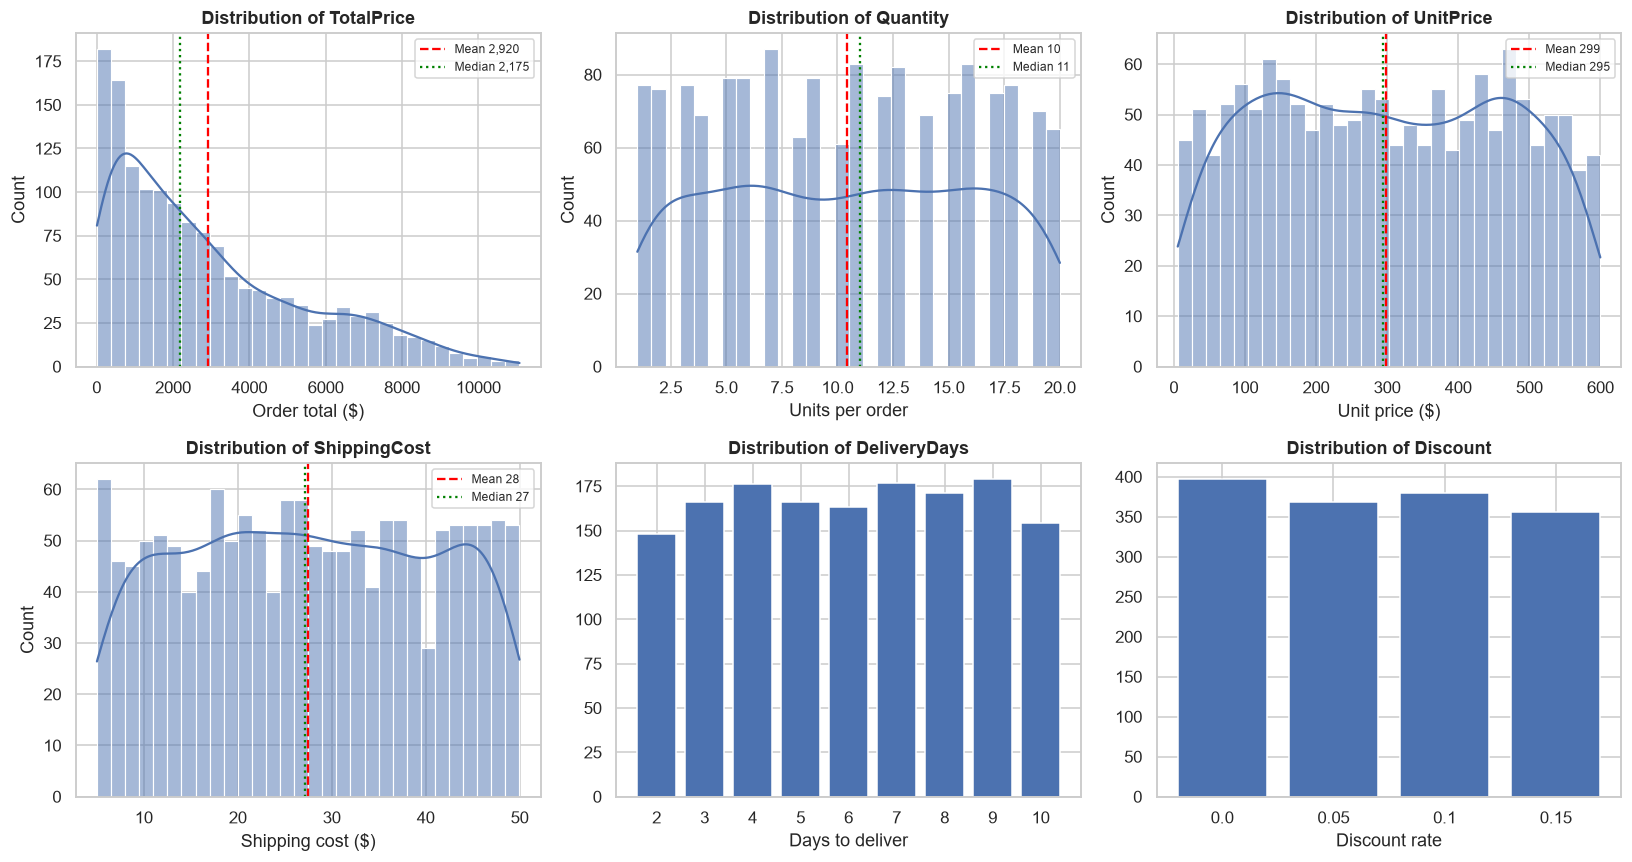

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

plots = [
    ("TotalPrice",    "Order total ($)",        "hist"),
    ("Quantity",      "Units per order",        "hist"),
    ("UnitPrice",     "Unit price ($)",         "hist"),
    ("ShippingCost",  "Shipping cost ($)",      "hist"),
    ("DeliveryDays",  "Days to deliver",        "bar"),
    ("Discount",      "Discount rate",          "bar"),
]

for ax, (col, label, kind) in zip(axes.ravel(), plots):
    if kind == "hist":
        sns.histplot(df[col], bins=30, kde=True, ax=ax, color=PALETTE[0])
        ax.axvline(df[col].mean(),   color="red",   ls="--", label=f"Mean {df[col].mean():,.0f}")
        ax.axvline(df[col].median(), color="green", ls=":",  label=f"Median {df[col].median():,.0f}")
        ax.legend(fontsize=8)
    else:
        counts = df[col].value_counts().sort_index()
        ax.bar(counts.index.astype(str), counts.values, color=PALETTE[0])
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(label)

plt.tight_layout()
plt.show()

### 5.3 Category Balance

Counts orders in each category. Imbalance matters for comparisons: a category with very few orders gives less reliable averages.

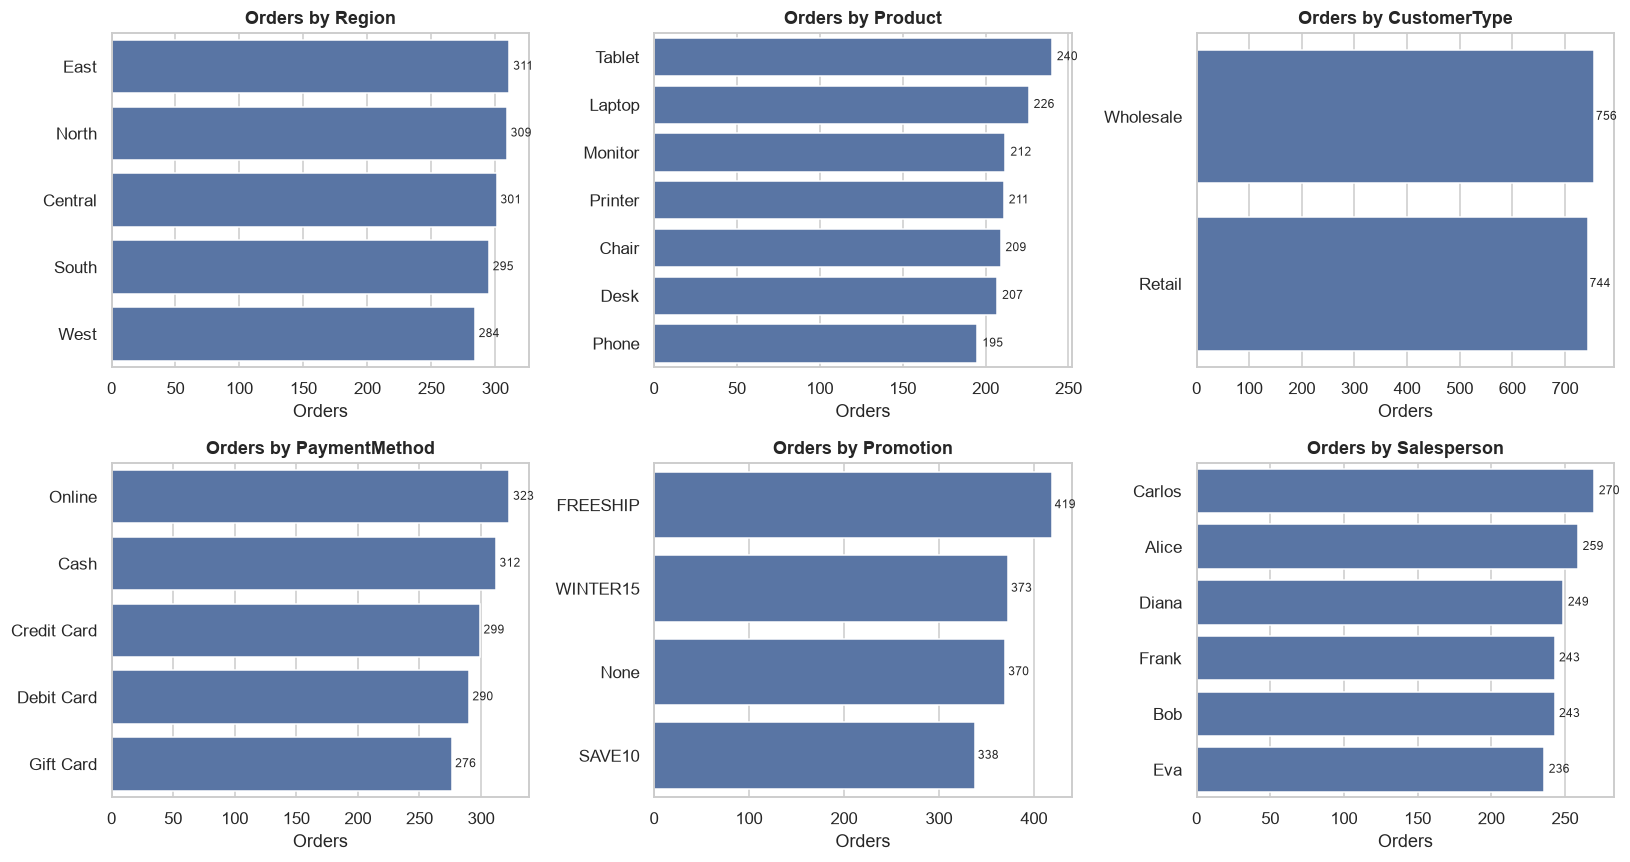

In [17]:
cat_plot_cols = ["Region", "Product", "CustomerType", "PaymentMethod", "Promotion", "Salesperson"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), cat_plot_cols):
    counts = df[col].value_counts()
    sns.barplot(x=counts.values, y=counts.index, ax=ax, color=PALETTE[0])
    ax.set_title(f"Orders by {col}")
    ax.set_xlabel("Orders")
    ax.set_ylabel("")
    for i, v in enumerate(counts.values):
        ax.text(v + 3, i, str(v), va="center", fontsize=8)

plt.tight_layout()
plt.show()

### 5.4 Outlier Detection

Uses the IQR (interquartile range) rule. Values more than 1.5 × IQR outside the middle 50% are flagged.

**Decision:** Outliers are flagged but **kept**. Each one is a valid, large order (for example, 20 units of a high-priced item) and not a data entry error. Removing them would understate real revenue.

In [18]:
def iqr_outliers(series, k=1.5):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - k * iqr, q3 + k * iqr
    return (series < lower) | (series > upper), lower, upper

outlier_report = []
for col in ["TotalPrice", "Quantity", "UnitPrice", "ShippingCost", "DeliveryDays"]:
    mask, lo, hi = iqr_outliers(df[col])
    outlier_report.append({"column": col, "outliers": int(mask.sum()),
                           "pct": mask.mean() * 100, "lower_bound": lo, "upper_bound": hi})

pd.DataFrame(outlier_report).style.format({"pct": "{:.2f}%", "lower_bound": "{:,.1f}", "upper_bound": "{:,.1f}"})

,column,outliers,pct,lower_bound,upper_bound
0,TotalPrice,17,1.13%,"-4,454.2","9,736.1"
1,Quantity,0,0.00%,-10.0,30.0
2,UnitPrice,0,0.00%,-292.5,890.2
3,ShippingCost,0,0.00%,-16.2,71.5
4,DeliveryDays,0,0.00%,-2.0,14.0


### 5.5 Correlation Overview

Pearson correlation between numeric variables. Expect a strong link between `Quantity` and `TotalPrice`, since order value is units times price. That relationship is mechanical, so it says little about customer behaviour. The more useful checks are whether `Returned` relates to shipping, delivery time or discount.

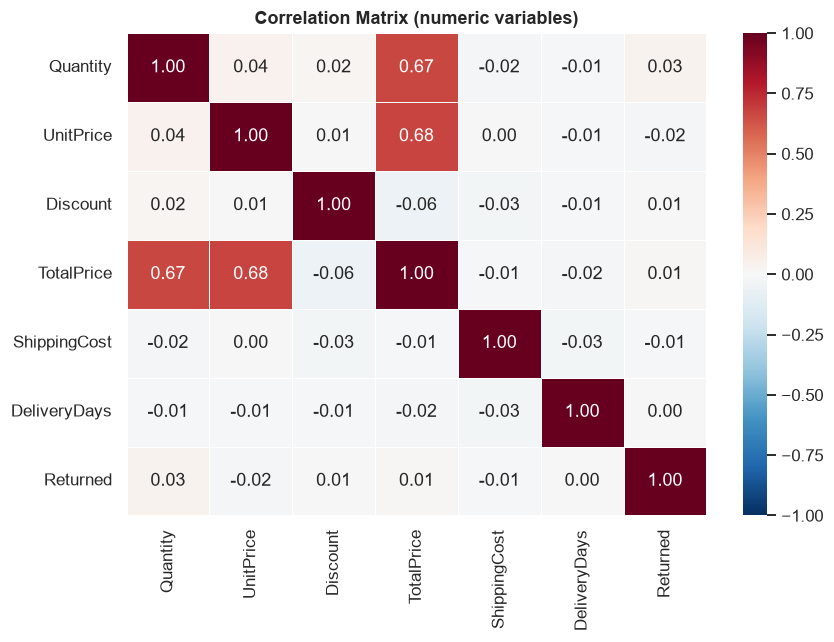

In [19]:
corr_cols = ["Quantity", "UnitPrice", "Discount", "TotalPrice", "ShippingCost", "DeliveryDays", "Returned"]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, ax=ax, linewidths=0.5)
ax.set_title("Correlation Matrix (numeric variables)")
plt.tight_layout()
plt.show()

## 6. Business Performance Analysis

This section turns the cleaned data into business metrics: revenue, average order value (AOV), return rate, and how each dimension performs.

### 6.1 Headline KPIs

The key numbers for a leadership summary. Gross revenue counts every order. Net revenue removes returned orders, and that gap is the cost of returns.

In [20]:
kpis = {
    "Total orders":                 len(df),
    "Gross revenue ($)":            df["TotalPrice"].sum(),
    "Returned revenue ($)":         df["ReturnedRevenue"].sum(),
    "Net revenue ($)":              df["NetRevenue"].sum(),
    "Return rate (orders)":         df["Returned"].mean(),
    "Return rate (revenue)":        df["ReturnedRevenue"].sum() / df["TotalPrice"].sum(),
    "Average order value ($)":      df["TotalPrice"].mean(),
    "Median order value ($)":       df["TotalPrice"].median(),
    "Units sold":                   df["Quantity"].sum(),
    "Discount given ($)":           df["DiscountAmount"].sum(),
    "Average discount rate":        df["Discount"].mean(),
    "Shipping cost total ($)":      df["ShippingCost"].sum(),
    "Unique customers":             df["CustomerName"].nunique(),
    "Average delivery days":        df["DeliveryDays"].mean(),
}

print(f"{'KPI':<32}{'Value':>16}")
print("-" * 48)
for name, value in kpis.items():
    if "rate" in name.lower():
        text = f"{value:.1%}"
    elif value >= 100:
        text = f"{value:,.0f}"
    else:
        text = f"{value:,.2f}"
    print(f"{name:<32}{text:>16}")

KPI                                        Value
------------------------------------------------
Total orders                               1,500
Gross revenue ($)                      4,379,992
Returned revenue ($)                   1,110,090
Net revenue ($)                        3,269,903
Return rate (orders)                       24.8%
Return rate (revenue)                      25.3%
Average order value ($)                    2,920
Median order value ($)                     2,175
Units sold                                15,616
Discount given ($)                       347,901
Average discount rate                       7.3%
Shipping cost total ($)                   41,261
Unique customers                           1,371
Average delivery days                       6.04


### 6.2 Performance by Region

Compares regions on revenue, order count, average order value and return rate. `RevenueShare` shows each region's share of total revenue.

In [21]:
region = (df.groupby("Region")
            .agg(Orders=("OrderID", "size"),
                 Revenue=("TotalPrice", "sum"),
                 AOV=("TotalPrice", "mean"),
                 ReturnRate=("Returned", "mean"),
                 Units=("Quantity", "sum"))
            .assign(RevenueShare=lambda d: d["Revenue"] / d["Revenue"].sum())
            .sort_values("Revenue", ascending=False))

region.style.format({"Revenue": "${:,.0f}", "AOV": "${:,.0f}", "ReturnRate": "{:.1%}",
                     "RevenueShare": "{:.1%}", "Units": "{:,.0f}", "Orders": "{:,.0f}"})

,Orders,Revenue,AOV,ReturnRate,Units,RevenueShare
Region,,,,,,
North,309,"$967,958","$3,133",22.7%,"3,442",22.1%
East,311,"$883,634","$2,841",26.0%,"3,078",20.2%
West,284,"$853,479","$3,005",26.1%,"3,041",19.5%
Central,301,"$847,154","$2,814",23.3%,"3,102",19.3%
South,295,"$827,768","$2,806",26.1%,"2,953",18.9%


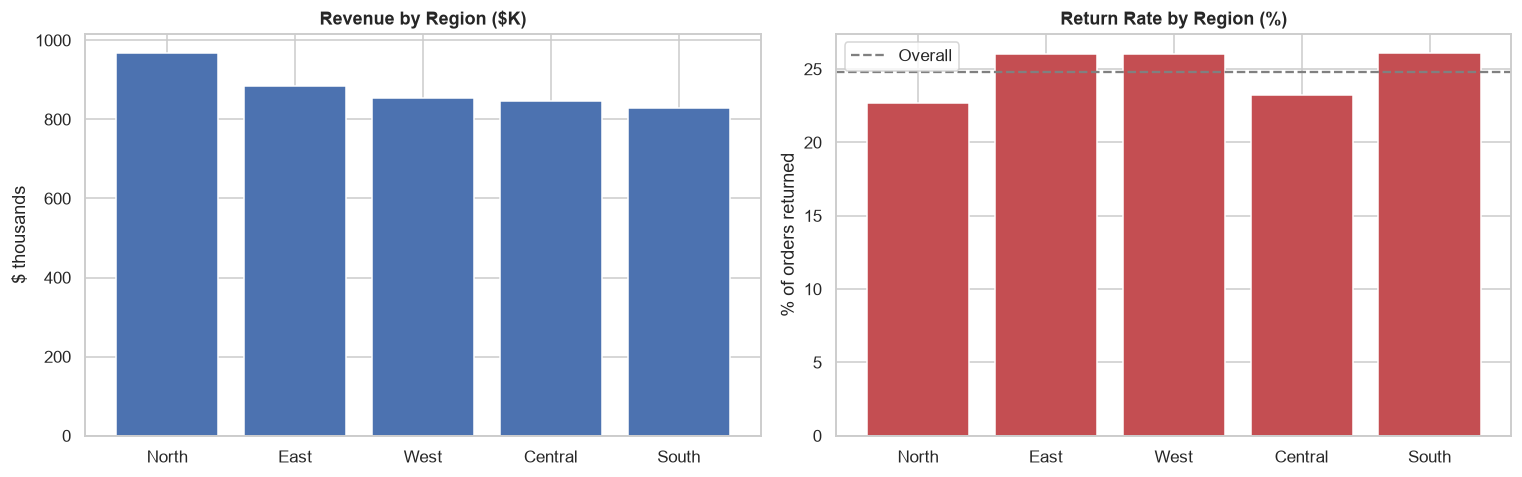

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].bar(region.index, region["Revenue"] / 1e3, color=PALETTE[0])
axes[0].set_title("Revenue by Region ($K)")
axes[0].set_ylabel("$ thousands")

axes[1].bar(region.index, region["ReturnRate"] * 100, color=PALETTE[3])
axes[1].axhline(df["Returned"].mean() * 100, ls="--", color="grey", label="Overall")
axes[1].set_title("Return Rate by Region (%)")
axes[1].set_ylabel("% of orders returned")
axes[1].legend()

plt.tight_layout()
plt.show()

### 6.3 Performance by Product

Compares products on revenue, volume and return rate. The average unit price is included to show whether revenue differences come from price or from volume.

In [23]:
product = (df.groupby("Product")
             .agg(Orders=("OrderID", "size"),
                  Units=("Quantity", "sum"),
                  Revenue=("TotalPrice", "sum"),
                  AvgUnitPrice=("UnitPrice", "mean"),
                  ReturnRate=("Returned", "mean"))
             .assign(RevenueShare=lambda d: d["Revenue"] / d["Revenue"].sum())
             .sort_values("Revenue", ascending=False))

product.style.format({"Revenue": "${:,.0f}", "AvgUnitPrice": "${:,.2f}", "ReturnRate": "{:.1%}",
                      "RevenueShare": "{:.1%}", "Units": "{:,.0f}", "Orders": "{:,.0f}"})

,Orders,Units,Revenue,AvgUnitPrice,ReturnRate,RevenueShare
Product,,,,,,
Tablet,240,"2,577","$684,539",$282.58,24.2%,15.6%
Laptop,226,"2,408","$684,417",$303.73,27.4%,15.6%
Printer,211,"2,336","$684,387",$301.93,22.3%,15.6%
Monitor,212,"2,177","$651,629",$317.30,26.4%,14.9%
Chair,209,"2,122","$622,589",$319.70,28.2%,14.2%
Desk,207,"2,026","$555,267",$295.18,21.7%,12.7%
Phone,195,"1,970","$497,163",$271.19,23.1%,11.4%


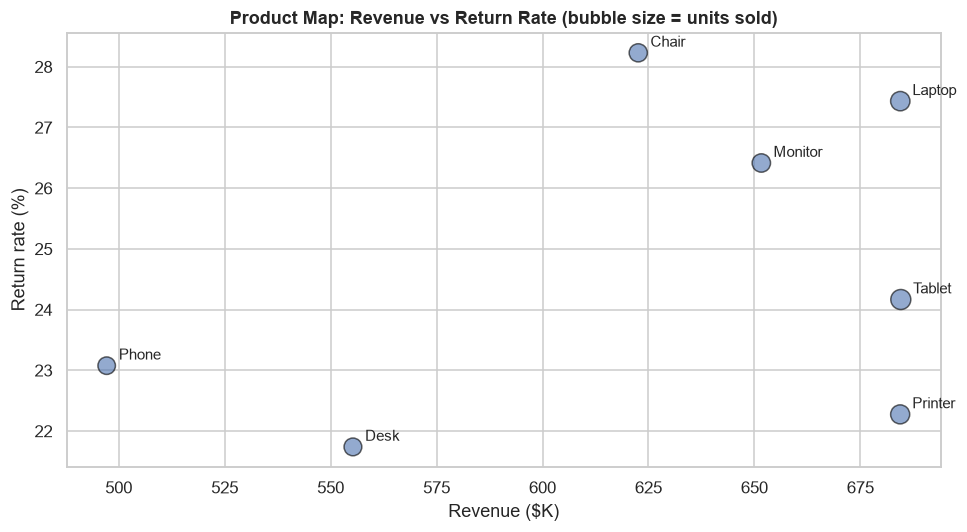

In [24]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(product["Revenue"] / 1e3, product["ReturnRate"] * 100, s=product["Units"] / 15,
           alpha=0.6, color=PALETTE[0], edgecolor="black")
for name, row in product.iterrows():
    ax.annotate(name, (row["Revenue"] / 1e3, row["ReturnRate"] * 100),
                textcoords="offset points", xytext=(8, 4), fontsize=10)
ax.set_xlabel("Revenue ($K)")
ax.set_ylabel("Return rate (%)")
ax.set_title("Product Map: Revenue vs Return Rate (bubble size = units sold)")
plt.tight_layout()
plt.show()

### 6.4 Performance Over Time

Two views are used:
- **Monthly trend with a 3-month rolling average**, to show direction and smooth out noise.
- **Half-year totals**, for a fair comparison. 2025 contains only January to June, so comparing full years would be misleading. Comparing H1 with H1 and H2 with H2 avoids that problem.

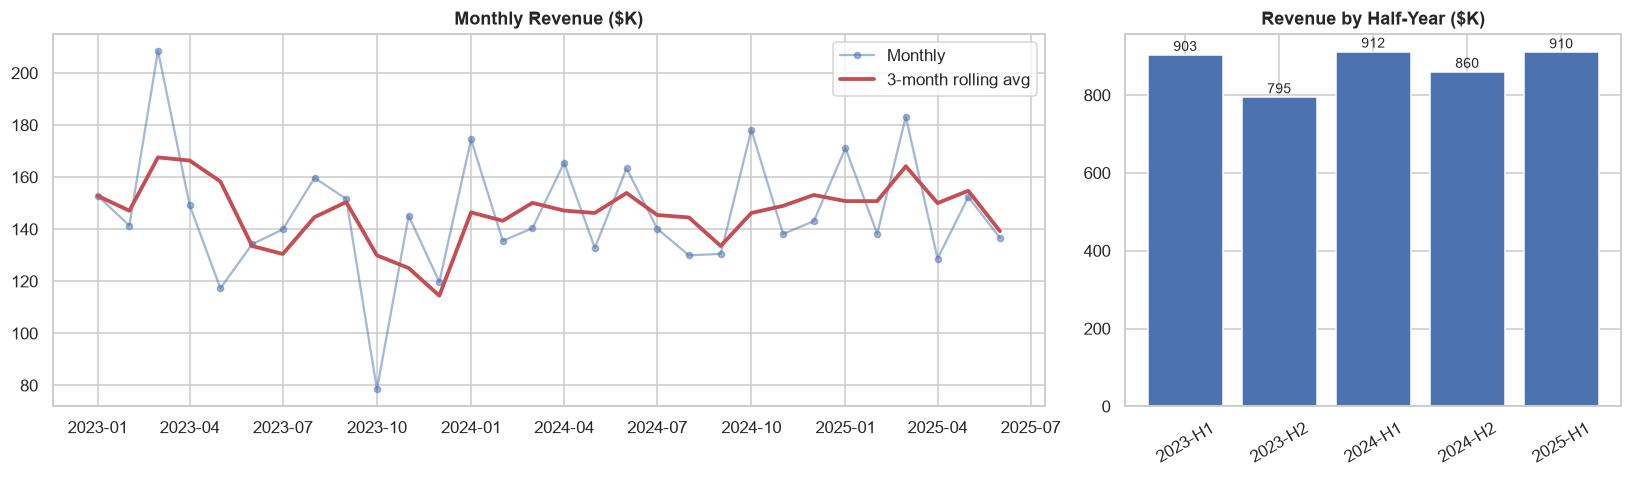

,Revenue,Orders,Change_vs_prev_half
Half,,,
2023-H1,"$903,340",295,+nan%
2023-H2,"$794,530",284,-12.0%
2024-H1,"$911,988",305,+14.8%
2024-H2,"$859,967",279,-5.7%
2025-H1,"$910,168",337,+5.8%


In [25]:
monthly = (df.groupby("YearMonth")
             .agg(Revenue=("TotalPrice", "sum"), Orders=("OrderID", "size")))
monthly["Rolling3M"] = monthly["Revenue"].rolling(3, min_periods=1).mean()

half = (df.groupby("Half")
          .agg(Revenue=("TotalPrice", "sum"), Orders=("OrderID", "size")))
half["Change_vs_prev_half"] = half["Revenue"].pct_change()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2, 1]})

axes[0].plot(monthly.index, monthly["Revenue"] / 1e3, marker="o", ms=4, alpha=0.5, label="Monthly")
axes[0].plot(monthly.index, monthly["Rolling3M"] / 1e3, lw=2.5, color=PALETTE[3], label="3-month rolling avg")
axes[0].set_title("Monthly Revenue ($K)")
axes[0].legend()

axes[1].bar(half.index, half["Revenue"] / 1e3, color=PALETTE[0])
axes[1].set_title("Revenue by Half-Year ($K)")
for i, v in enumerate(half["Revenue"] / 1e3):
    axes[1].text(i, v + 10, f"{v:,.0f}", ha="center", fontsize=9)
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

half.style.format({"Revenue": "${:,.0f}", "Orders": "{:,.0f}", "Change_vs_prev_half": "{:+.1%}"})

### 6.5 Channel and Sales Team Performance

Compares customer type, payment method, store, and salesperson. The function below gives the same table format for each, so results are easy to compare.

In [26]:
def group_summary(col, sort_by="Revenue"):
    t = (df.groupby(col)
           .agg(Orders=("OrderID", "size"),
                Revenue=("TotalPrice", "sum"),
                AOV=("TotalPrice", "mean"),
                ReturnRate=("Returned", "mean")))
    return t.sort_index() if sort_by == "index" else t.sort_values(sort_by, ascending=False)

fmt = {"Revenue": "${:,.0f}", "AOV": "${:,.0f}", "ReturnRate": "{:.1%}", "Orders": "{:,.0f}"}

for col in ["CustomerType", "PaymentMethod", "StoreLocation", "Salesperson"]:
    print(f"\n--- {col} ---")
    display(group_summary(col).style.format(fmt))


--- CustomerType ---


,Orders,Revenue,AOV,ReturnRate
CustomerType,,,,
Retail,744,"$2,195,526","$2,951",25.4%
Wholesale,756,"$2,184,467","$2,890",24.2%



--- PaymentMethod ---


,Orders,Revenue,AOV,ReturnRate
PaymentMethod,,,,
Online,323,"$971,115","$3,007",23.8%
Cash,312,"$950,388","$3,046",30.8%
Credit Card,299,"$866,483","$2,898",21.7%
Gift Card,276,"$821,585","$2,977",20.3%
Debit Card,290,"$770,421","$2,657",26.9%



--- StoreLocation ---


,Orders,Revenue,AOV,ReturnRate
StoreLocation,,,,
Store D,400,"$1,205,526","$3,014",25.0%
Store A,372,"$1,088,513","$2,926",24.7%
Store C,365,"$1,056,305","$2,894",22.5%
Store B,363,"$1,029,649","$2,836",27.0%



--- Salesperson ---


,Orders,Revenue,AOV,ReturnRate
Salesperson,,,,
Bob,243,"$796,781","$3,279",26.3%
Alice,259,"$786,166","$3,035",24.7%
Frank,243,"$714,642","$2,941",22.6%
Carlos,270,"$707,167","$2,619",28.1%
Eva,236,"$698,670","$2,960",21.6%
Diana,249,"$676,568","$2,717",24.9%


### 6.6 Discounts and Promotions

Checks whether discounts and promotion codes are linked to bigger orders or fewer returns. If they are not, that spend is hard to justify.

--- Discount level ---


,Orders,Revenue,AOV,ReturnRate
Discount,,,,
0.000000,397,"$1,217,674","$3,067",25.4%
0.050000,368,"$1,127,901","$3,065",23.4%
0.100000,379,"$1,078,306","$2,845",24.3%
0.150000,356,"$956,111","$2,686",26.1%


--- Promotion code ---


,Orders,Revenue,AOV,ReturnRate
Promotion,,,,
FREESHIP,419,"$1,238,077","$2,955",23.9%
WINTER15,373,"$1,078,012","$2,890",24.7%
None,370,"$1,074,247","$2,903",24.9%
SAVE10,338,"$989,657","$2,928",26.0%


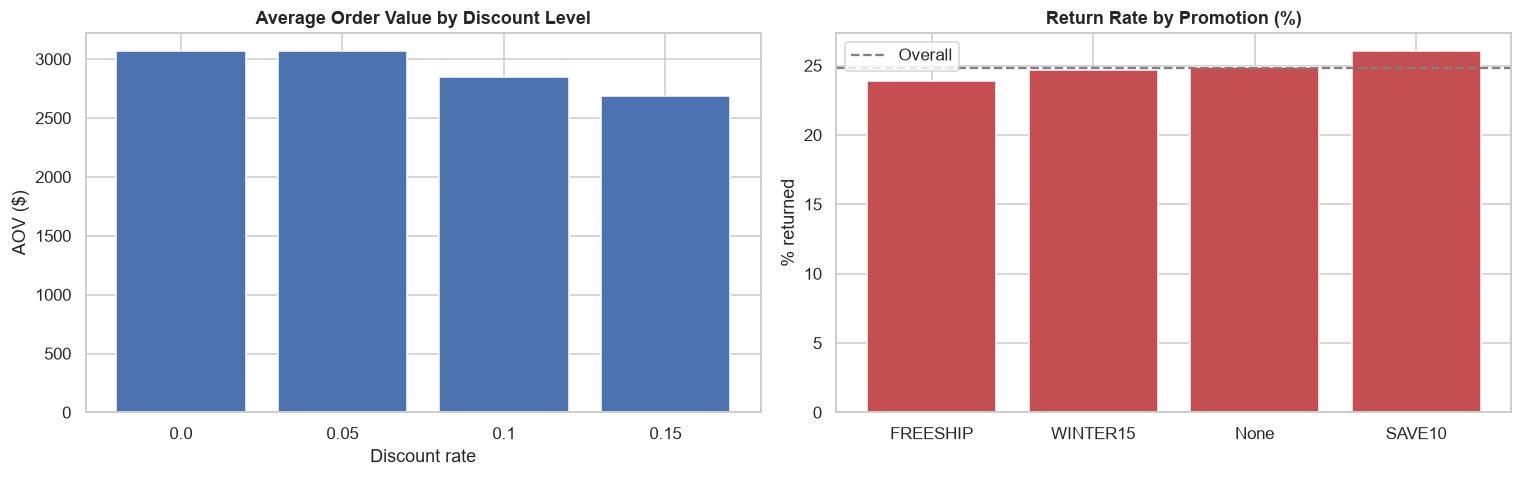

In [27]:
print("--- Discount level ---")
display(group_summary("Discount", sort_by="index").style.format(fmt))

print("--- Promotion code ---")
display(group_summary("Promotion").style.format(fmt))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

disc = group_summary("Discount", sort_by="index")
axes[0].bar(disc.index.astype(str), disc["AOV"], color=PALETTE[0])
axes[0].set_title("Average Order Value by Discount Level")
axes[0].set_xlabel("Discount rate")
axes[0].set_ylabel("AOV ($)")

promo = group_summary("Promotion")
axes[1].bar(promo.index, promo["ReturnRate"] * 100, color=PALETTE[3])
axes[1].axhline(df["Returned"].mean() * 100, ls="--", color="grey", label="Overall")
axes[1].set_title("Return Rate by Promotion (%)")
axes[1].set_ylabel("% returned")
axes[1].legend()

plt.tight_layout()
plt.show()

### 6.7 What Drives Returns?

This is the most important business question. A 25% return rate means a quarter of orders are lost. The following charts compare return rates across each categorical variable, with 95% confidence intervals. The intervals show how much a rate could move by chance. Wide, overlapping intervals mean the gap may be noise.

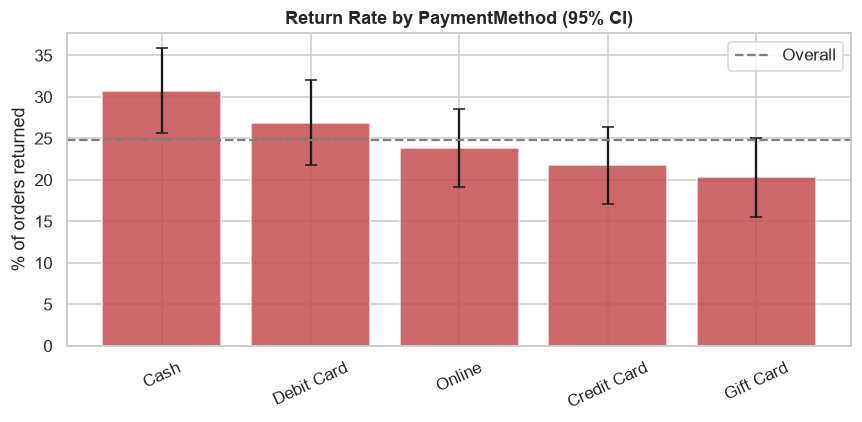

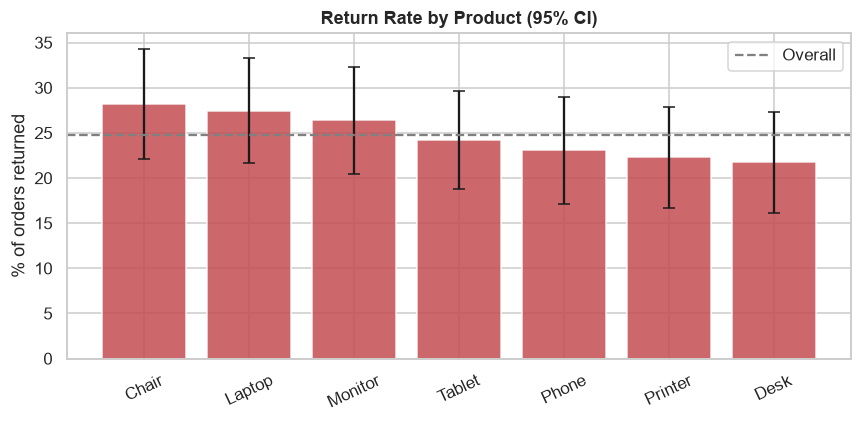

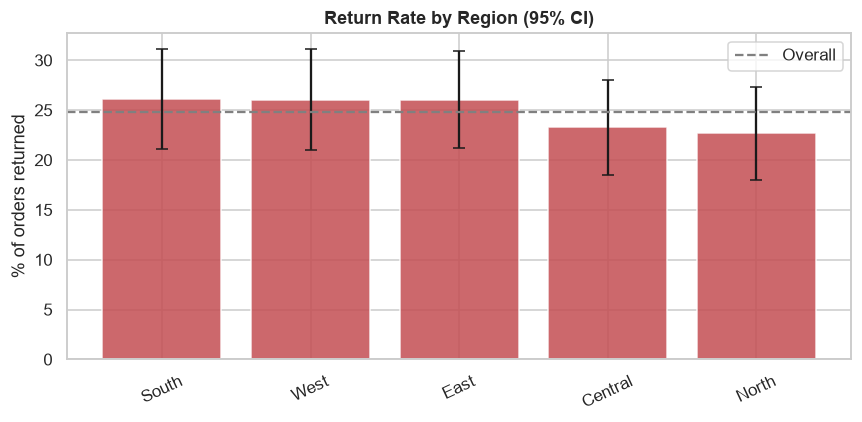

,Orders,ReturnRate,CI95
PaymentMethod,,,
Cash,312,30.8%,±5.1%
Debit Card,290,26.9%,±5.1%
Online,323,23.8%,±4.6%
Credit Card,299,21.7%,±4.7%
Gift Card,276,20.3%,±4.7%


In [28]:
def rate_table(col):
    t = (df.groupby(col)
           .agg(Orders=("Returned", "size"), ReturnRate=("Returned", "mean")))
    t["CI95"] = 1.96 * np.sqrt(t["ReturnRate"] * (1 - t["ReturnRate"]) / t["Orders"])
    return t.sort_values("ReturnRate", ascending=False)

def plot_return_rate(col):
    t = rate_table(col)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(t.index.astype(str), t["ReturnRate"] * 100, yerr=t["CI95"] * 100,
           capsize=4, color=PALETTE[3], alpha=0.85)
    ax.axhline(df["Returned"].mean() * 100, ls="--", color="grey", label="Overall")
    ax.set_title(f"Return Rate by {col} (95% CI)")
    ax.set_ylabel("% of orders returned")
    ax.legend()
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()

for col in ["PaymentMethod", "Product", "Region"]:
    plot_return_rate(col)

display(rate_table("PaymentMethod").style.format({"ReturnRate": "{:.1%}", "CI95": "±{:.1%}"}))

### 6.8 Shipping, Delivery and Returns

Tests whether operational factors, meaning shipping cost and delivery time, relate to returns. If slow or expensive deliveries are returned more often, that points to fulfilment as a fix. Mean values are compared, and the correlations are tested formally in Section 7.

In [29]:
ops = (df.assign(DeliveryBucket=pd.cut(df["DeliveryDays"], bins=[0, 4, 7, 10],
                                        labels=["2-4 days", "5-7 days", "8-10 days"]))
         .groupby("DeliveryBucket", observed=True)
         .agg(Orders=("OrderID", "size"), ReturnRate=("Returned", "mean"),
              AvgShipping=("ShippingCost", "mean")))

ops.style.format({"ReturnRate": "{:.1%}", "AvgShipping": "${:,.2f}", "Orders": "{:,.0f}"})

,Orders,ReturnRate,AvgShipping
DeliveryBucket,,,
2-4 days,490,25.1%,$28.04
5-7 days,506,25.3%,$27.40
8-10 days,504,24.0%,$27.09


## 7. Statistical Analysis

The business tables above show differences. This section tests whether those differences are real or could be random variation.

Method:
1. **Estimate uncertainty:** confidence intervals for average order value and return rate.
2. **Test hypotheses:** choose the right test for each question (ANOVA, Kruskal-Wallis, Welch's t-test, chi-square, correlation).
3. **Measure effect size:** statistical significance does not show whether a difference is large. Effect sizes do.
4. **Correct for multiple testing:** running many tests raises the chance of a false positive. Bonferroni correction is applied.

### 7.1 Confidence Intervals

- **Average order value:** uses both a t-based interval and a bootstrap interval. Order values are right-skewed, so the bootstrap (resampling the data 5,000 times) is the more reliable check.
- **Return rate:** normal-approximation interval for a proportion, which is accurate at this sample size.

In [30]:
aov = df["TotalPrice"]
n = len(aov)
mean_aov = aov.mean()
se = aov.std(ddof=1) / np.sqrt(n)
t_ci = mean_aov + np.array([-1, 1]) * stats.t.ppf(0.975, n - 1) * se

boot_means = np.array([rng.choice(aov.values, size=n, replace=True).mean() for _ in range(5000)])
boot_ci = np.percentile(boot_means, [2.5, 97.5])

p_hat = df["Returned"].mean()
p_ci = p_hat + np.array([-1, 1]) * 1.96 * np.sqrt(p_hat * (1 - p_hat) / n)

print(f"Average order value : ${mean_aov:,.2f}")
print(f"  t-based 95% CI    : (${t_ci[0]:,.2f}, ${t_ci[1]:,.2f})")
print(f"  bootstrap 95% CI  : (${boot_ci[0]:,.2f}, ${boot_ci[1]:,.2f})")
print(f"\nReturn rate         : {p_hat:.2%}")
print(f"  95% CI            : ({p_ci[0]:.2%}, {p_ci[1]:.2%})")

Average order value : $2,919.99
  t-based 95% CI    : ($2,792.22, $3,047.77)
  bootstrap 95% CI  : ($2,791.90, $3,050.02)

Return rate         : 24.80%
  95% CI            : (22.61%, 26.99%)


### 7.2 Hypothesis Tests

Each row tests one business question against a null hypothesis (no real difference).

| Question | Test | Why this test |
|---|---|---|
| Do regions differ in order value? | One-way ANOVA | Compares means across 3+ groups |
| Do products differ in order value? | Kruskal-Wallis | Non-parametric, safe for skewed data |
| Do wholesale and retail differ in order value? | Welch's t-test | Two groups, unequal variance |
| Do salespeople differ in order value? | One-way ANOVA | Compares means across groups |
| Is return rate linked to a category? | Chi-square test of independence | Two categorical variables |
| Does order size track quantity? | Pearson correlation | Two numeric variables |
| Are returns linked to shipping cost or delivery time? | Point-biserial correlation | Binary vs numeric |

**Effect sizes reported:**
- η² (eta-squared): share of variance explained. Roughly 0.01 small, 0.06 medium, 0.14 large.
- Cramér's V: strength of association for categorical tests. 0.1 small, 0.3 medium.
- Cohen's d: standardised difference between two means. 0.2 small, 0.5 medium, 0.8 large.

In [31]:
def eta_squared(values, groups):
    grand_mean = values.mean()
    ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for _, g in values.groupby(groups))
    ss_total = ((values - grand_mean) ** 2).sum()
    return ss_between / ss_total

def cramers_v(table):
    chi2, p, _, _ = stats.chi2_contingency(table)
    n_obs = table.values.sum()
    k = min(table.shape) - 1
    return chi2, p, np.sqrt(chi2 / (n_obs * k))

def cohens_d(a, b):
    pooled = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    return (a.mean() - b.mean()) / pooled

results = []

# --- Order value (TotalPrice) questions ---
f, p = stats.f_oneway(*[g["TotalPrice"] for _, g in df.groupby("Region")])
results.append(["Order value differs by Region", "One-way ANOVA", f, p,
                eta_squared(df["TotalPrice"], df["Region"]), "eta²"])

h, p = stats.kruskal(*[g["TotalPrice"] for _, g in df.groupby("Product")])
results.append(["Order value differs by Product", "Kruskal-Wallis", h, p,
                (h - 7 + 1) / (len(df) - 7), "epsilon² (approx.)"])

f, p = stats.f_oneway(*[g["TotalPrice"] for _, g in df.groupby("Salesperson")])
results.append(["Order value differs by Salesperson", "One-way ANOVA", f, p,
                eta_squared(df["TotalPrice"], df["Salesperson"]), "eta²"])

w = df.loc[df["CustomerType"] == "Wholesale", "TotalPrice"]
r = df.loc[df["CustomerType"] == "Retail", "TotalPrice"]
t, p = stats.ttest_ind(w, r, equal_var=False)
results.append(["Order value: Wholesale vs Retail", "Welch t-test", t, p, cohens_d(w, r), "Cohen's d"])

h, p = stats.kruskal(*[g["TotalPrice"] for _, g in df.groupby("Discount")])
results.append(["Order value differs by Discount level", "Kruskal-Wallis", h, p,
                (h - 3) / (len(df) - 4), "epsilon² (approx.)"])

h, p = stats.kruskal(*[g["TotalPrice"] for _, g in df.groupby("Promotion")])
results.append(["Order value differs by Promotion", "Kruskal-Wallis", h, p,
                (h - 3) / (len(df) - 4), "epsilon² (approx.)"])

r_val, p = stats.pearsonr(df["Quantity"], df["TotalPrice"])
results.append(["Order value correlates with Quantity", "Pearson r", r_val, p, r_val, "r"])

# --- Return questions (binary outcome) ---
for col, label in [("Region", "Region"), ("Product", "Product"), ("CustomerType", "CustomerType"),
                   ("Salesperson", "Salesperson"), ("PaymentMethod", "PaymentMethod"),
                   ("StoreLocation", "StoreLocation"), ("Promotion", "Promotion"),
                   ("Discount", "Discount level")]:
    chi2, p, v = cramers_v(pd.crosstab(df[col], df["Returned"]))
    results.append([f"Return rate differs by {label}", "Chi-square", chi2, p, v, "Cramér's V"])

r_val, p = stats.pointbiserialr(df["Returned"], df["ShippingCost"])
results.append(["Return rate correlates with Shipping cost", "Point-biserial r", r_val, p, r_val, "r"])

r_val, p = stats.pointbiserialr(df["Returned"], df["DeliveryDays"])
results.append(["Return rate correlates with Delivery days", "Point-biserial r", r_val, p, r_val, "r"])

tests_df = pd.DataFrame(results, columns=["Hypothesis", "Test", "Statistic", "p_value", "Effect", "Effect_metric"])
m = len(tests_df)
tests_df["p_bonferroni"] = np.minimum(tests_df["p_value"] * m, 1.0)
tests_df["Verdict"] = np.select(
    [tests_df["p_bonferroni"] < 0.05, tests_df["p_value"] < 0.05],
    ["Significant (survives correction)", "Nominal only (fails correction)"],
    default="Not significant",
)

print(f"Tests run: {m}  |  Bonferroni threshold: {0.05 / m:.4f}")
tests_df.style.format({"Statistic": "{:.3f}", "p_value": "{:.4f}", "Effect": "{:.3f}",
                       "p_bonferroni": "{:.4f}"})

Tests run: 17  |  Bonferroni threshold: 0.0029


,Hypothesis,Test,Statistic,p_value,Effect,Effect_metric,p_bonferroni,Verdict
0,Order value differs by Region,One-way ANOVA,0.987,0.4133,0.003,eta²,1.0000,Not significant
1,Order value differs by Product,Kruskal-Wallis,10.147,0.1186,0.003,epsilon² (approx.),1.0000,Not significant
2,Order value differs by Salesperson,One-way ANOVA,2.206,0.0513,0.007,eta²,0.8725,Not significant
3,Order value: Wholesale vs Retail,Welch t-test,-0.472,0.6372,-0.024,Cohen's d,1.0000,Not significant
4,Order value differs by Discount level,Kruskal-Wallis,4.532,0.2094,0.001,epsilon² (approx.),1.0000,Not significant
5,Order value differs by Promotion,Kruskal-Wallis,0.340,0.9524,-0.002,epsilon² (approx.),1.0000,Not significant
6,Order value correlates with Quantity,Pearson r,0.666,0.0000,0.666,r,0.0000,Significant (survives correction)
7,Return rate differs by Region,Chi-square,1.915,0.7514,0.036,Cramér's V,1.0000,Not significant
8,Return rate differs by Product,Chi-square,4.579,0.5989,0.055,Cramér's V,1.0000,Not significant
9,Return rate differs by CustomerType,Chi-square,0.227,0.6334,0.012,Cramér's V,1.0000,Not significant


### 7.3 Interpreting the Return-Rate Differences

The payment-method result is the only test that is nominally significant on its own. The Verdict column shows whether it survives the correction for the number of tests run. Where it does not, it should be treated as a hypothesis to check with new data, not as a proven effect.

The chart below shows the payment-method rates with confidence intervals, which makes the size of the gap visible.

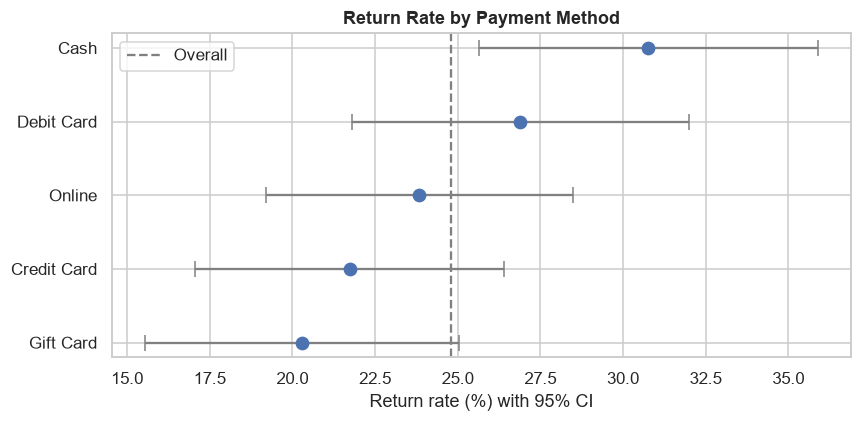

In [32]:
pay = rate_table("PaymentMethod").sort_values("ReturnRate")

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(pay["ReturnRate"] * 100, pay.index, xerr=pay["CI95"] * 100, fmt="o",
            color=PALETTE[0], ecolor="grey", capsize=5, ms=8)
ax.axvline(df["Returned"].mean() * 100, ls="--", color="grey", label="Overall")
ax.set_xlabel("Return rate (%) with 95% CI")
ax.set_title("Return Rate by Payment Method")
ax.legend()
plt.tight_layout()
plt.show()

### 7.4 Save the Statistical Results

Saves each test with its effect size and corrected p-value, so the conclusions can be checked later.

In [33]:
tests_df.to_csv(OUT / "hypothesis_tests.csv", index=False)
print("Saved:", OUT / "hypothesis_tests.csv")

Saved: outputs\hypothesis_tests.csv


## 8. Storytelling: From Numbers to Decisions

### 8.1 Executive Summary

Between January 2023 and June 2025, the business booked **$4.38M** in gross order value from 1,500 orders. The average order is **$2,920**. Around **25% of that revenue, $1.11M, came back as returns**, which leaves **$3.27M** in net revenue. Overall performance is stable, but returns are the single largest problem in the data.

### 8.2 Key Findings

**1. Returns are the biggest lever.**
A quarter of revenue is lost to returns. Lowering the return rate by a few points would be worth more than most growth initiatives. Return reasons are not recorded in this dataset, so the cause cannot yet be identified.

**2. Revenue is stable, with a mild second-half dip.**
Each first half brought in about $900K. The second half was lower in both years (about 12% lower in 2023 and 6% lower in 2024). H1 2025 ($910K) is flat against H1 2024 ($912K), so there is no sign of decline.

**3. Region and product differences are small.**
North leads on revenue ($968K, 22% of total) and average order value ($3,133). South is lowest. However, the regional differences are not statistically significant (ANOVA p = 0.41). Products show a similar pattern: Tablets lead and Phones trail, but the difference is not significant (p = 0.12). Average unit prices fall in a narrow $271–$320 band for every product, so revenue differences come mostly from volume.

**4. Promotions show no measurable effect.**
Orders with a promo code have about the same average value and return rate as orders without one. Promotion type is not linked to order value (p = 0.95) or to returns (p = 0.92).

**5. Discounts do not clearly buy bigger baskets.**
Orders with a 15% discount average about 12% less than orders with no discount. The difference is not statistically significant, though, and discounts are not linked to returns.

**6. Payment method may relate to returns.**
Cash orders are returned at 31%, compared with 20% for gift cards. This is the strongest pattern in the data, but it does not hold up after correcting for the number of tests run. Treat it as a lead to investigate.

**7. Operations do not explain returns.**
Shipping cost and delivery time have no meaningful link to returns (p = 0.75 and p = 0.94). Speed and cost of delivery are not the problem.

**8. Salespeople differ in average order value, but only marginally.**
Bob has the highest average order ($3,279) and Diana the lowest ($2,717). The overall test is borderline (p = 0.05).

### 8.3 Recommendations

| Priority | Recommendation | Why |
|---|---|---|
| 1 | **Start a returns root-cause review** and add a `ReturnReason` field to the order system | 25% of revenue is returned, and the cause is currently unknown |
| 2 | **Investigate cash orders**: check whether they go through an inspection or refund process different from other payment types | The 31% vs 20% gap is large enough to be worth a targeted test |
| 3 | **Run a controlled test of promotions** (hold out a random group) before renewing spend | No measurable lift in order value or returns is visible |
| 4 | **Set discount guardrails** for deep discounts (for example, above 10%) | Deeper discounts are not linked to larger orders |
| 5 | **Check the price list**: average unit prices are almost identical across products | Either the catalogue is misconfigured or pricing strategy is missing |
| 6 | **Add cost and margin data** | Revenue is known, but profit is not. Discount and return decisions should be judged on margin |
| 7 | **Use one regional playbook**, and monitor West and South return rates | Regions perform alike, so a shared approach makes sense |

### 8.4 Caveats and Limitations

- **Revenue is not profit.** There are no cost or margin fields, so the analysis cannot say which products are actually profitable.
- **Returns are a flag, not a process.** The data has no return date, refund amount or reason, so the true cost of each return is unknown.
- **Correlation is not causation.** Associations, such as payment method and returns, suggest where to look but do not prove cause.
- **Multiple testing.** 17 tests were run, so some results may be chance findings. The Verdict column accounts for this.
- **The data looks partly synthetic.** Near-identical prices across products and generic customer names (`Cust NNNN`) are unusual for real sales records. Confirm the source before acting on small differences.
- **Partial final year.** 2025 covers only January to June, so full-year comparisons are not valid. Half-year comparisons are used instead.

### 8.5 Next Steps

1. **Predict returns:** train a classification model (for example, logistic regression or gradient boosting) on the order features, and check which ones matter most.
2. **Forecast revenue:** fit a time-series model (SARIMA or Prophet) once more history is available.
3. **Run an A/B test** on promotions and discount levels.
4. **Add profitability analysis** once cost data is available.
5. **Build a live dashboard** (Power BI, Tableau or Streamlit) on top of `sales_clean.csv`.

### 8.6 Detailed Dashboard

A summary view that brings together the main findings. Each panel supports one of the points above.

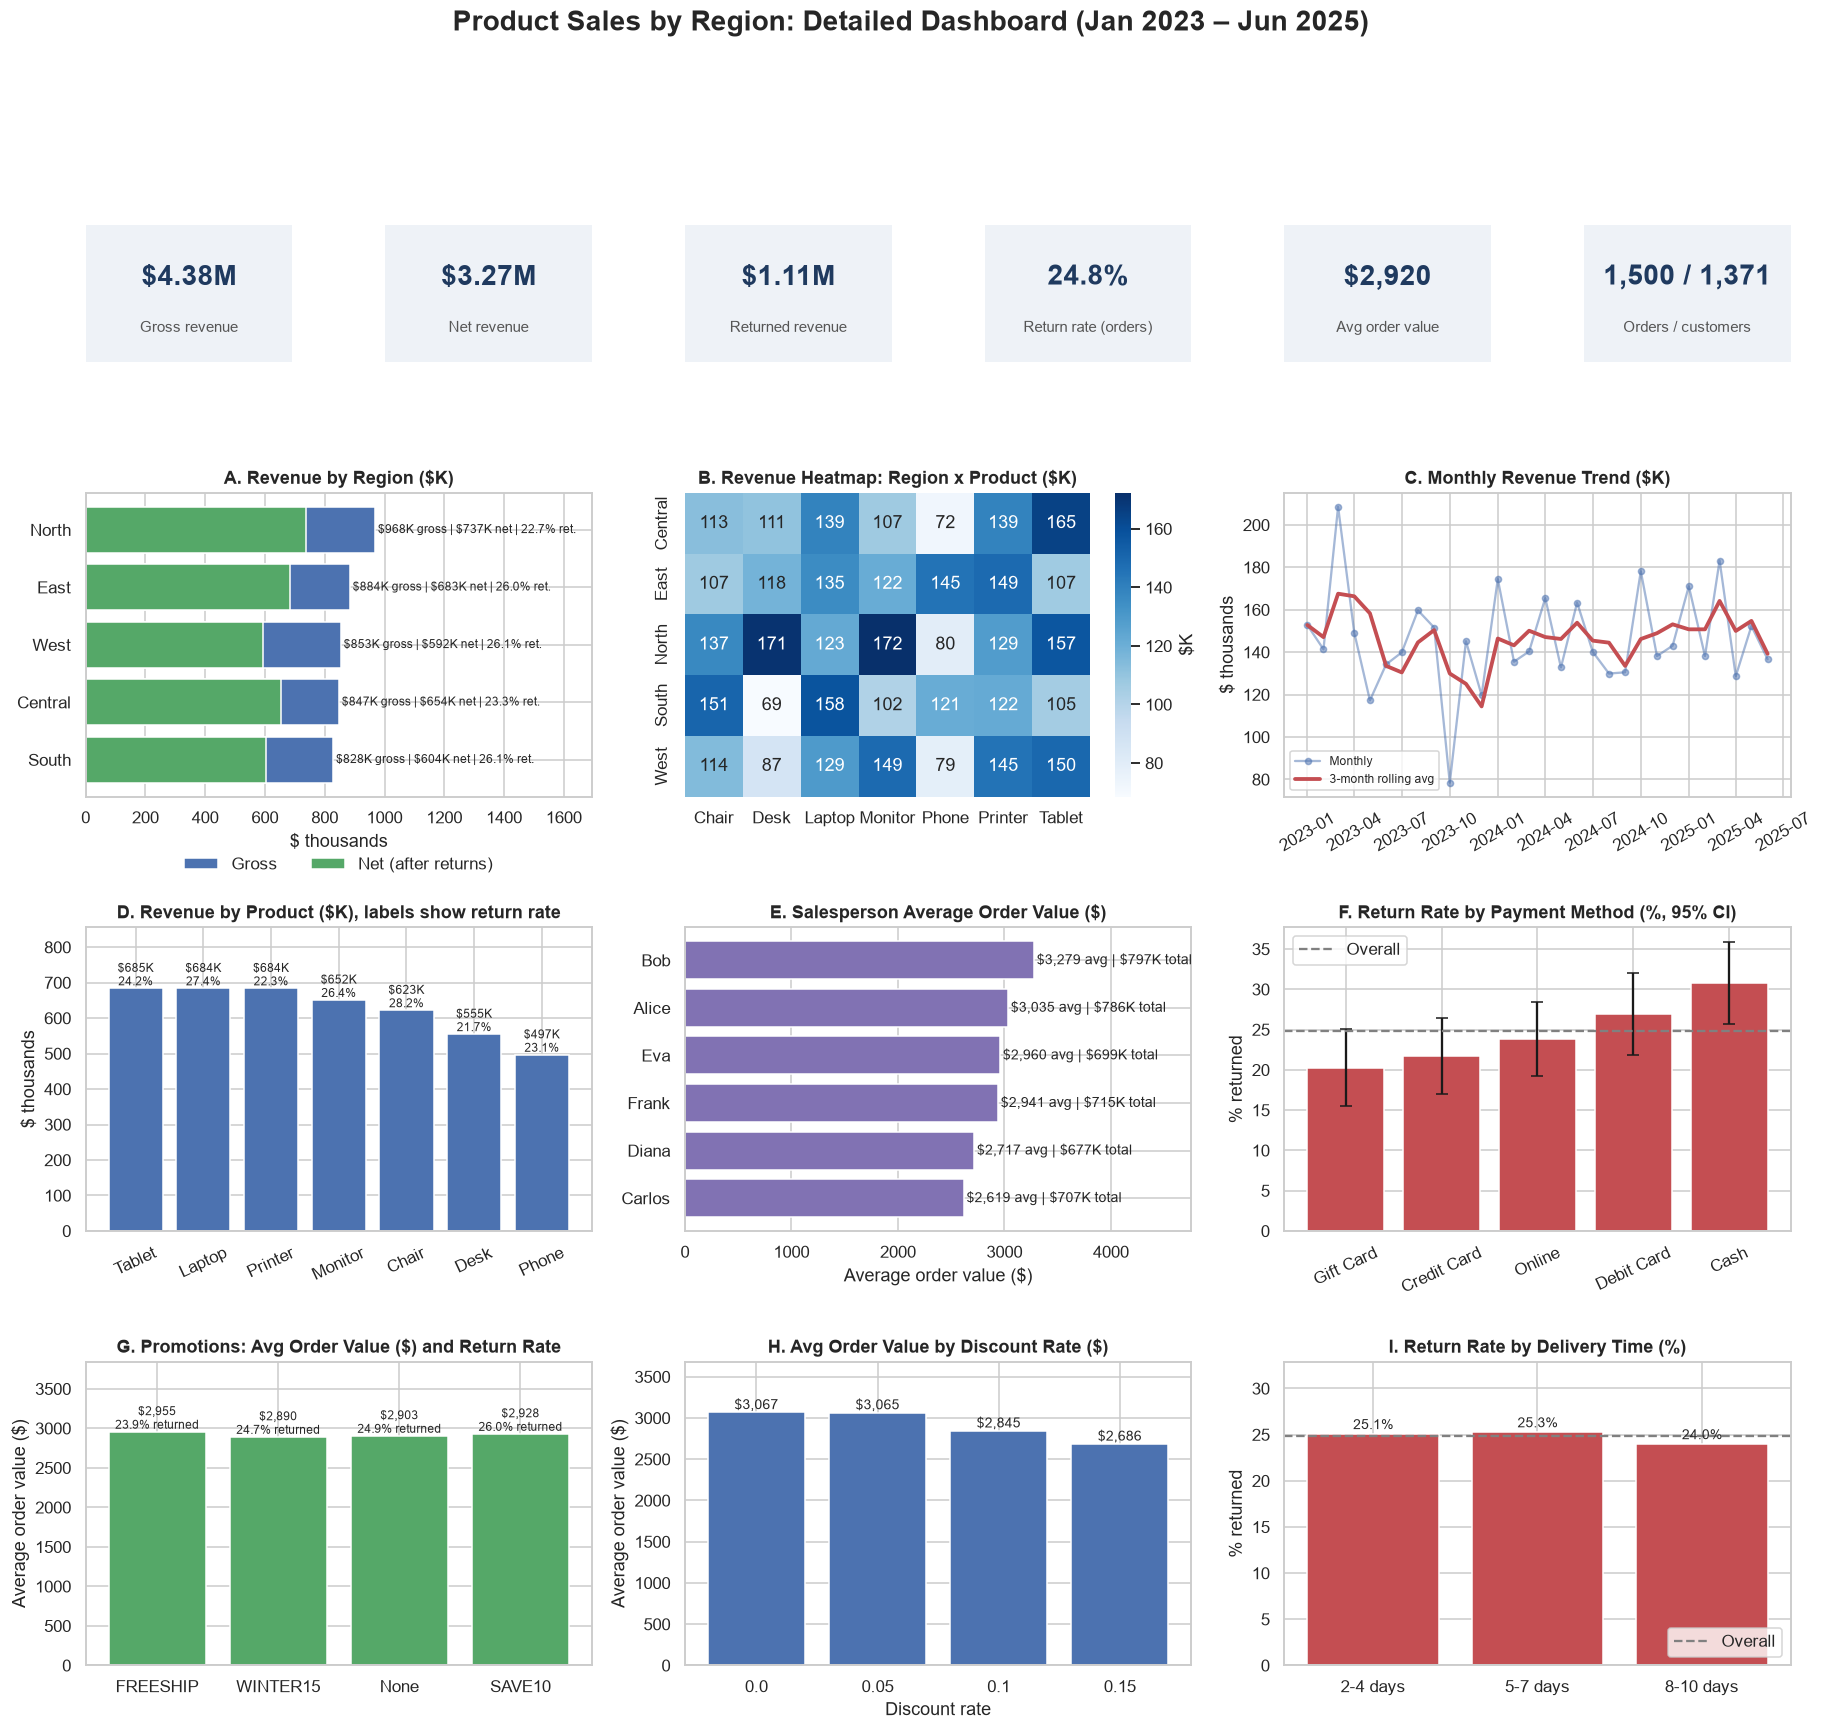

In [34]:
fig = plt.figure(figsize=(20, 17))
gs = fig.add_gridspec(4, 6, height_ratios=[0.45, 1, 1, 1], hspace=0.5, wspace=0.45)

# ---- Row 0: KPI tiles ----
tiles = [
    ("Gross revenue",         f"\\${df['TotalPrice'].sum() / 1e6:,.2f}M"),
    ("Net revenue",           f"\\${df['NetRevenue'].sum() / 1e6:,.2f}M"),
    ("Returned revenue",      f"\\${df['ReturnedRevenue'].sum() / 1e6:,.2f}M"),
    ("Return rate (orders)",  f"{df['Returned'].mean():.1%}"),
    ("Avg order value",       f"\\${df['TotalPrice'].mean():,.0f}"),
    ("Orders / customers",    f"{len(df):,} / {df['CustomerName'].nunique():,}"),
]
for i, (label, value) in enumerate(tiles):
    ax = fig.add_subplot(gs[0, i])
    ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, color="#eef2f7"))
    ax.text(0.5, 0.62, value, ha="center", va="center", fontsize=18, fontweight="bold", color="#1f3a5f")
    ax.text(0.5, 0.25, label, ha="center", va="center", fontsize=10, color="#555555")

# ---- Row 1: Region, Region x Product, Monthly trend ----
reg = (df.groupby("Region").agg(Gross=("TotalPrice", "sum"), Net=("NetRevenue", "sum"),
                               RR=("Returned", "mean")).sort_values("Gross"))
ax = fig.add_subplot(gs[1, 0:2])
ax.barh(reg.index, reg["Gross"] / 1e3, color=PALETTE[0], label="Gross")
ax.barh(reg.index, reg["Net"] / 1e3, color=PALETTE[2], label="Net (after returns)")
ax.set_xlim(0, reg["Gross"].max() / 1e3 * 1.75)
for i, (g, n, rr) in enumerate(zip(reg["Gross"] / 1e3, reg["Net"] / 1e3, reg["RR"])):
    ax.text(g + 10, i, f"\\${g:,.0f}K gross | \\${n:,.0f}K net | {rr:.1%} ret.", va="center", fontsize=8)
ax.set_title("A. Revenue by Region ($K)")
ax.set_xlabel("$ thousands")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)

ax = fig.add_subplot(gs[1, 2:4])
pivot = df.pivot_table(index="Region", columns="Product", values="TotalPrice", aggfunc="sum") / 1e3
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar_kws={"label": "$K"})
ax.set_title("B. Revenue Heatmap: Region x Product ($K)")
ax.set_xlabel("")
ax.set_ylabel("")

ax = fig.add_subplot(gs[1, 4:6])
monthly_rev = df.groupby("YearMonth")["TotalPrice"].sum() / 1e3
ax.plot(monthly_rev.index, monthly_rev.values, marker="o", ms=4, alpha=0.5, color=PALETTE[0], label="Monthly")
ax.plot(monthly_rev.index, monthly_rev.rolling(3, min_periods=1).mean(), lw=2.5, color=PALETTE[3],
        label="3-month rolling avg")
ax.set_title("C. Monthly Revenue Trend ($K)")
ax.set_ylabel("$ thousands")
ax.legend(loc="lower left", fontsize=8)
ax.tick_params(axis="x", rotation=30)

# ---- Row 2: Product, Salesperson, Payment ----
prod = (df.groupby("Product").agg(Gross=("TotalPrice", "sum"), RR=("Returned", "mean"))
          .sort_values("Gross", ascending=False))
ax = fig.add_subplot(gs[2, 0:2])
bars = ax.bar(prod.index, prod["Gross"] / 1e3, color=PALETTE[0])
ax.set_title("D. Revenue by Product ($K), labels show return rate")
ax.set_ylabel("$ thousands")
ax.tick_params(axis="x", rotation=25)
for bar, (g, rr) in zip(bars, zip(prod["Gross"] / 1e3, prod["RR"])):
    ax.text(bar.get_x() + bar.get_width() / 2, g + 8, f"\\${g:,.0f}K\n{rr:.1%}",
            ha="center", fontsize=8)
ax.set_ylim(0, prod["Gross"].max() / 1e3 * 1.25)

sp = df.groupby("Salesperson")["TotalPrice"].agg(["mean", "sum"]).sort_values("mean")
ax = fig.add_subplot(gs[2, 2:4])
ax.barh(sp.index, sp["mean"], color=PALETTE[4])
for i, (m, t) in enumerate(zip(sp["mean"], sp["sum"])):
    ax.text(m + 25, i, f"\\${m:,.0f} avg | \\${t / 1e3:,.0f}K total", va="center", fontsize=9)
ax.set_xlim(0, sp["mean"].max() * 1.45)
ax.set_title("E. Salesperson Average Order Value ($)")
ax.set_xlabel("Average order value ($)")

pay = rate_table("PaymentMethod").sort_values("ReturnRate")
ax = fig.add_subplot(gs[2, 4:6])
ax.bar(pay.index, pay["ReturnRate"] * 100, yerr=pay["CI95"] * 100, capsize=4, color=PALETTE[3])
ax.axhline(df["Returned"].mean() * 100, ls="--", color="grey", label="Overall")
ax.set_title("F. Return Rate by Payment Method (%, 95% CI)")
ax.set_ylabel("% returned")
ax.tick_params(axis="x", rotation=25)
ax.legend()

# ---- Row 3: Promotion, Discount, Delivery ----
promo_t = group_summary("Promotion")
ax = fig.add_subplot(gs[3, 0:2])
ax.bar(promo_t.index, promo_t["AOV"], color=PALETTE[2])
for i, v in enumerate(promo_t["AOV"]):
    ax.text(i, v + 40, f"\\${v:,.0f}\n{promo_t['ReturnRate'].iloc[i]:.1%} returned", ha="center", fontsize=8)
ax.set_ylim(0, promo_t["AOV"].max() * 1.3)
ax.set_title("G. Promotions: Avg Order Value ($) and Return Rate")
ax.set_ylabel("Average order value ($)")

disc_t = group_summary("Discount", sort_by="index")
ax = fig.add_subplot(gs[3, 2:4])
ax.bar(disc_t.index.astype(str), disc_t["AOV"], color=PALETTE[0])
for i, v in enumerate(disc_t["AOV"]):
    ax.text(i, v + 40, f"\\${v:,.0f}", ha="center", fontsize=9)
ax.set_ylim(0, disc_t["AOV"].max() * 1.2)
ax.set_title("H. Avg Order Value by Discount Rate ($)")
ax.set_xlabel("Discount rate")
ax.set_ylabel("Average order value ($)")

dd = (df.assign(Bucket=pd.cut(df["DeliveryDays"], bins=[0, 4, 7, 10],
                               labels=["2-4 days", "5-7 days", "8-10 days"]))
        .groupby("Bucket", observed=True)["Returned"].mean() * 100)
ax = fig.add_subplot(gs[3, 4:6])
ax.bar(dd.index.astype(str), dd.values, color=PALETTE[3])
for i, v in enumerate(dd.values):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center", fontsize=9)
ax.axhline(df["Returned"].mean() * 100, ls="--", color="grey", label="Overall")
ax.set_ylim(0, dd.max() * 1.3)
ax.set_title("I. Return Rate by Delivery Time (%)")
ax.set_ylabel("% returned")
ax.legend(loc="lower right")

fig.suptitle("Product Sales by Region: Detailed Dashboard (Jan 2023 – Jun 2025)",
             fontsize=18, fontweight="bold", y=0.995)
plt.show()

### 8.7 Export Summary Tables

Saves the key tables to one Excel workbook, so finance or regional managers can open them without running the notebook.

In [35]:
export_path = OUT / "sales_summary_tables.xlsx"
with pd.ExcelWriter(export_path) as writer:
    region.to_excel(writer, sheet_name="Region")
    product.to_excel(writer, sheet_name="Product")
    half.to_excel(writer, sheet_name="HalfYear")
    group_summary("PaymentMethod").to_excel(writer, sheet_name="Payment")
    group_summary("Salesperson").to_excel(writer, sheet_name="Salesperson")
    tests_df.to_excel(writer, sheet_name="Hypothesis_Tests", index=False)

print("Saved:", export_path)

Saved: outputs\sales_summary_tables.xlsx


---
**Conclusion.** Sales are steady at about $900K per half-year, and region, product and promotion differences are small. The clearest opportunity is returns: a quarter of revenue is lost. Recording return reasons and investigating the payment-method pattern are the first steps.